# BÁO CÁO THỰC HÀNH LAB 3: NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM
## HỌC PHẦN: CSE457 – XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
### TRƯỜNG ĐẠI HỌC THỦY LỢI • KHOA CÔNG NGHỆ THÔNG TIN • BỘ MÔN TRÍ TUỆ NHÂN TẠO

---
* **Họ và tên**: Hồ Đức Minh
* **MSSV**: 2351260669
* **Lớp**: 65TTNT
* **Bài thực hành**: Lab 3 – Nhận dạng tiếng nói nâng cao với Hidden Markov Models (HMM)
* **Tập dữ liệu**: 5 khẩu lệnh tiếng Việt (`mo`, `dong`, `len`, `xuong`, `dung`) x 8 lần lặp x 16kHz mono WAV
---

## KIẾN TRÚC HỆ THỐNG
$$\text{WAV 16kHz} \longrightarrow \text{Pre-emphasis \& Trim} \longrightarrow \text{MFCC 39-D (13 + 13}\Delta + 13\Delta^2) \longrightarrow \text{CMVN} \longrightarrow \text{Left-to-Right Gaussian HMM} \longrightarrow \text{Viterbi / Bayes MAP} \longrightarrow \hat{W}$$


### 1. Khai báo thư viện

In [1]:
import time, math, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import librosa
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

FS = 16000
LABELS = ['mo', 'dong', 'len', 'xuong', 'dung']
LABEL_MAP_VI = {'mo': 'mở', 'dong': 'đóng', 'len': 'lên', 'xuong': 'xuống', 'dung': 'dừng'}
print("[OK] Thư viện sẵn sàng.")


[OK] Thư viện sẵn sàng.


### 2. Bước 1 — Trích xuất đặc trưng 39 chiều (MFCC + $\Delta$ + $\Delta^2$) và CMVN
- 13 MFCC tĩnh: đường bao phổ ngắn hạn
- 13 $\Delta$: vận tốc phổ $\Delta \mathbf{c}_t \approx \mathbf{c}_t - \mathbf{c}_{t-1}$
- 13 $\Delta^2$: gia tốc phổ $\Delta^2 \mathbf{c}_t \approx \Delta \mathbf{c}_t - \Delta \mathbf{c}_{t-1}$
- Utterance-level CMVN: chuẩn hóa trung bình và phương sai từng phát âm


In [2]:
def extract_feat(path_or_audio, sr=FS, n_mfcc=13, use_dynamic=True, use_cmvn=True):
    if isinstance(path_or_audio, (str, Path)):
        y, sr = librosa.load(path_or_audio, sr=sr, mono=True)
    else:
        y = np.asarray(path_or_audio, dtype=np.float32)
    y, _ = librosa.effects.trim(y, top_db=30)
    y = librosa.effects.preemphasis(y, coef=0.97)
    
    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=512,
        win_length=int(0.025 * sr), hop_length=int(0.010 * sr),
        window='hamming', n_mels=26, fmin=20, fmax=sr / 2
    )
    if use_dynamic:
        d1 = librosa.feature.delta(mfcc, order=1)
        d2 = librosa.feature.delta(mfcc, order=2)
        F = np.vstack([mfcc, d1, d2]).T
    else:
        F = mfcc.T
    if use_cmvn:
        mu = F.mean(axis=0, keepdims=True)
        sd = F.std(axis=0, keepdims=True) + 1e-8
        F = (F - mu) / sd
    return F

for sample in ['mo/mo_01.wav', 'dong/dong_01.wav', 'len/len_01.wav']:
    f = extract_feat(f"dataset/train/{sample}")
    print(f"{sample:18s} -> Shape: {f.shape} (T={f.shape[0]}, D={f.shape[1]})")


mo/mo_01.wav       -> Shape: (61, 39) (T=61, D=39)
dong/dong_01.wav   -> Shape: (58, 39) (T=58, D=39)
len/len_01.wav     -> Shape: (58, 39) (T=58, D=39)


### Trực quan hóa Heatmap đặc trưng cho 'mo' và 'dong'

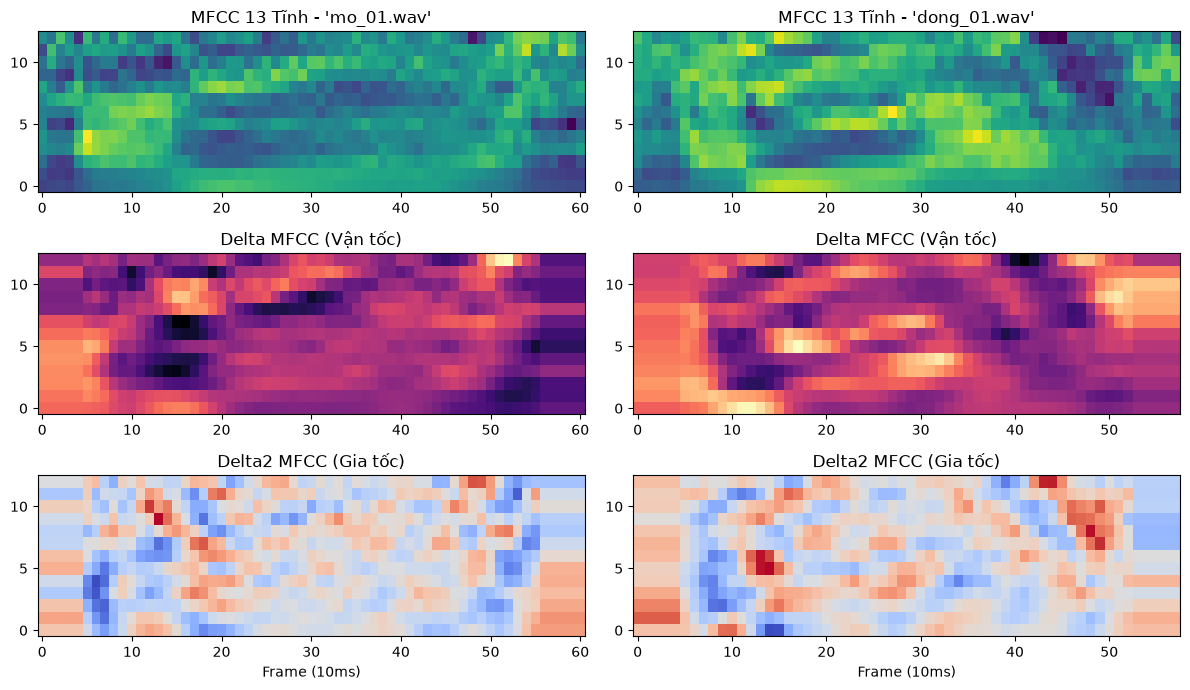

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(12, 7))
for c_idx, w in enumerate(['mo', 'dong']):
    F = extract_feat(f"dataset/train/{w}/{w}_01.wav")
    axes[0, c_idx].imshow(F[:, :13].T, aspect='auto', origin='lower', cmap='viridis')
    axes[0, c_idx].set_title(f"MFCC 13 Tĩnh - '{w}_01.wav'")
    axes[1, c_idx].imshow(F[:, 13:26].T, aspect='auto', origin='lower', cmap='magma')
    axes[1, c_idx].set_title("Delta MFCC (Vận tốc)")
    axes[2, c_idx].imshow(F[:, 26:39].T, aspect='auto', origin='lower', cmap='coolwarm')
    axes[2, c_idx].set_title("Delta2 MFCC (Gia tốc)")
    axes[2, c_idx].set_xlabel("Frame (10ms)")
plt.tight_layout()
plt.show()


### 3. Bước 2 — Khởi tạo HMM Left-to-Right (Bakis Topology)
- $\pi = [1, 0, 0, 0, 0]^T$: bắt đầu tại trạng thái 0
- $a_{ii} = 0.65, a_{i,i+1} = 0.35, a_{44} = 1.0$: chỉ cho phép self-loop và next-state
- `params='mc'`: cố định topology chuyển trạng thái, cập nhật Means và Covariances bằng Baum-Welch


In [4]:
def make_lr_hmm(n_states=5, n_iter=80, covariance_type='diag', params='mc', random_state=42):
    model = GaussianHMM(
        n_components=n_states, covariance_type=covariance_type,
        n_iter=n_iter, tol=1e-3, min_covar=1e-3,
        init_params='mc', params=params, random_state=random_state
    )
    start = np.zeros(n_states); start[0] = 1.0
    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i] = 0.65; A[i, i + 1] = 0.35
    A[-1, -1] = 1.0
    model.startprob_ = start
    model.transmat_ = A
    return model

m_init = make_lr_hmm(5)
print("pi ban đầu:", m_init.startprob_)
print("Transmat A ban đầu:\n", np.round(m_init.transmat_, 3))


pi ban đầu: [1. 0. 0. 0. 0.]
Transmat A ban đầu:
 [[0.65 0.35 0.   0.   0.  ]
 [0.   0.65 0.35 0.   0.  ]
 [0.   0.   0.65 0.35 0.  ]
 [0.   0.   0.   0.65 0.35]
 [0.   0.   0.   0.   1.  ]]


### 4. Bước 3 — Huấn luyện Whole-word HMM bằng Baum-Welch (EM)

In [5]:
train_dir = Path('dataset/train')
models, train_times = {}, {}

for l in LABELS:
    wavs = sorted((train_dir / l).glob('*.wav'))
    t0 = time.time()
    feats = [extract_feat(str(w)) for w in wavs]
    X = np.vstack(feats)
    m = make_lr_hmm(5)
    m.fit(X, [len(f) for f in feats])
    dt = time.time() - t0
    models[l] = m; train_times[l] = dt
    print(f"Từ '{l:6s}': Hội tụ={m.monitor_.converged:1d} | Vòng lặp={m.monitor_.iter:2d} | Thời gian train={dt*1000:6.1f} ms")


Từ 'mo    ': Hội tụ=1 | Vòng lặp=24 | Thời gian train= 565.4 ms


Từ 'dong  ': Hội tụ=1 | Vòng lặp=41 | Thời gian train= 283.8 ms


Từ 'len   ': Hội tụ=1 | Vòng lặp=36 | Thời gian train= 210.6 ms


Từ 'xuong ': Hội tụ=1 | Vòng lặp=37 | Thời gian train= 244.4 ms
Từ 'dung  ': Hội tụ=1 | Vòng lặp= 5 | Thời gian train=  55.8 ms


### 5. Bước 4 — Nhận dạng Maximum Likelihood trên tập kiểm thử
$$\hat{w} = \arg\max_{w \in \mathcal{V}} \log P(X | \lambda_w)$$


In [6]:
test_dir = Path('dataset/test')
true_y, pred_y, all_scores = [], [], {}

for l in LABELS:
    for w in sorted((test_dir / l).glob('*.wav')):
        F = extract_feat(str(w))
        scs = {cand: float(m.score(F)) for cand, m in models.items()}
        pred = max(scs, key=scs.get)
        true_y.append(l); pred_y.append(pred)
        all_scores[w.name] = (l, pred, scs)

print(f"{'Utterance':12s} | {'True':6s} | {'Pred':6s} | " + " | ".join([f"{l:9s}" for l in LABELS]))
print("-" * 80)
for sample in ['mo_07.wav', 'dong_07.wav', 'len_07.wav', 'xuong_07.wav', 'dung_07.wav']:
    lbl, pred, scs = all_scores[sample]
    print(f"{sample:12s} | {lbl:6s} | {pred:6s} | " + " | ".join([f"{scs[k]:9.1f}" for k in LABELS]))


Utterance    | True   | Pred   | mo        | dong      | len       | xuong     | dung     
--------------------------------------------------------------------------------
mo_07.wav    | mo     | mo     |   -5924.0 |   -7095.6 |   -8824.0 |   -6286.4 |   -7664.3
dong_07.wav  | dong   | dong   |   -3387.9 |   -3003.2 |   -4454.1 |   -3495.2 |   -3579.1
len_07.wav   | len    | len    |   -3957.4 |   -4054.4 |   -3088.9 |   -3889.5 |   -3922.5
xuong_07.wav | xuong  | xuong  |   -6504.7 |   -7095.6 |   -8938.5 |   -5823.6 |   -7514.3
dung_07.wav  | dung   | dung   |   -3400.5 |   -3637.0 |   -4072.4 |   -3563.8 |   -2906.8


### 6. Bước 5 — Căn chỉnh trạng thái Viterbi (State Alignment)
$$Q^* = \arg\max_Q P(X, Q | \lambda)$$


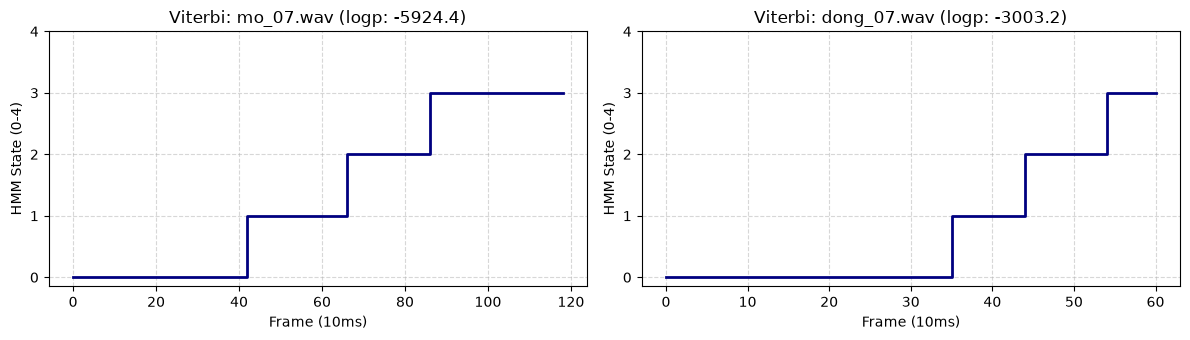

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for idx, target in enumerate(['mo', 'dong']):
    F = extract_feat(f"dataset/test/{target}/{target}_07.wav")
    logp, states = models[target].decode(F, algorithm='viterbi')
    axes[idx].step(range(len(states)), states, where='post', color='navy', lw=2)
    axes[idx].set_title(f"Viterbi: {target}_07.wav (logp: {logp:.1f})")
    axes[idx].set_xlabel("Frame (10ms)"); axes[idx].set_ylabel("HMM State (0-4)")
    axes[idx].set_yticks(range(5)); axes[idx].grid(True, ls='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 7. Bước 6 — Ma trận nhầm lẫn (Confusion Matrix) và Đánh giá

Độ chính xác tập kiểm thử: 100.0% (10/10)


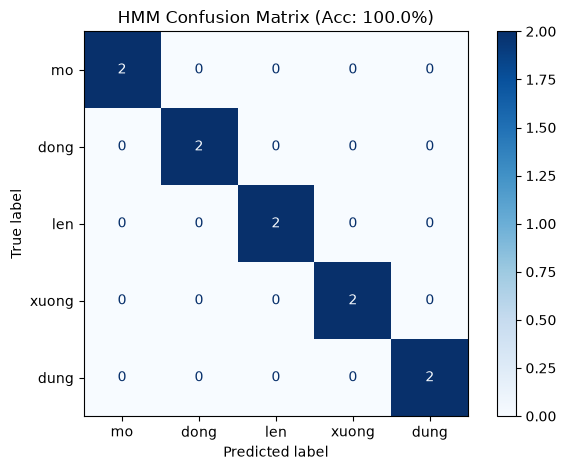

In [8]:
acc = accuracy_score(true_y, pred_y)
cm = confusion_matrix(true_y, pred_y, labels=LABELS)
print(f"Độ chính xác tập kiểm thử: {acc * 100:.1f}% ({sum(np.array(true_y) == np.array(pred_y))}/{len(true_y)})")

ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues')
plt.title(f"HMM Confusion Matrix (Acc: {acc*100:.1f}%)")
plt.tight_layout()
plt.show()


### 8. Bước 7 — So sánh đối trực diện HMM với DTW Baseline

In [9]:
def dtw_distance(X, Y):
    N, M = len(X), len(Y)
    if N == 0 or M == 0: return np.inf
    D = np.full((N + 1, M + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, N + 1):
        for j in range(1, M + 1):
            cost = np.linalg.norm(X[i - 1] - Y[j - 1])
            D[i, j] = cost + min(D[i - 1, j - 1], D[i - 1, j], D[i, j - 1])
    return D[N, M] / (N + M)

# DTW templates
templates = {l: [extract_feat(str(w)) for w in sorted((train_dir / l).glob('*.wav'))] for l in LABELS}

# DTW test
t0 = time.time()
pred_dtw = []
for l in LABELS:
    for w in sorted((test_dir / l).glob('*.wav')):
        f_t = extract_feat(str(w))
        best_d, best_l = min((min(dtw_distance(f_t, tpl) for tpl in tpls), cand)
                             for cand, tpls in templates.items())
        pred_dtw.append(best_l)
dtw_time = (time.time() - t0) / len(true_y)
dtw_acc = accuracy_score(true_y, pred_dtw)

# HMM test time
t0 = time.time()
for l in LABELS:
    for w in sorted((test_dir / l).glob('*.wav')):
        _ = max(m.score(extract_feat(str(w))) for m in models.values())
hmm_time = (time.time() - t0) / len(true_y)

print(f"{'Tiêu chí':28s} | {'DTW Baseline':16s} | {'HMM Model':16s}")
print("-" * 66)
print(f"{'Độ chính xác (Accuracy)':28s} | {dtw_acc*100:15.1f}% | {acc*100:15.1f}%")
print(f"{'Thời gian suy luận / trial':28s} | {dtw_time*1000:13.2f} ms | {hmm_time*1000:13.2f} ms")
print(f"{'Tốc độ tương đối':28s} | {'Baseline (1x)':16s} | {f'{dtw_time/hmm_time:.1f}x nhanh hơn':16s}")
print(f"{'Cơ chế căn chỉnh':28s} | {'Warping path':16s} | {'Viterbi state path':16s}")


Tiêu chí                     | DTW Baseline     | HMM Model       
------------------------------------------------------------------
Độ chính xác (Accuracy)      |           100.0% |           100.0%
Thời gian suy luận / trial   |        942.46 ms |         54.87 ms
Tốc độ tương đối             | Baseline (1x)    | 17.2x nhanh hơn 
Cơ chế căn chỉnh             | Warping path     | Viterbi state path


### 9. Bước 8 — Mở rộng Lexicon và Bigram MAP Re-ranking
$$\text{Score}(w) = \frac{\log P_A(X|w)}{T} + \lambda_{LM} \log P_{LM}(w | w_{\text{prev}})$$


In [10]:
# Đọc lexicon
lexicon = {}
with open("lexicon.txt", "r", encoding="utf-8") as f:
    for line in f:
        p = line.strip().split()
        if p: lexicon[p[0]] = p[1:]
print("Lexicon:", lexicon)

# Bigram counts có Add-k smoothing
corpus = [["mo", "len"], ["dong", "xuong"], ["mo", "dung"], ["dong", "dung"],
          ["len", "dung"], ["xuong", "dung"], ["len", "xuong"], ["xuong", "len"],
          ["mo", "dong"], ["dong", "mo"], ["mo", "len"], ["dong", "xuong"]]
c1, c2 = {}, {}
for sent in corpus:
    for i, w in enumerate(sent):
        c1[w] = c1.get(w, 0) + 1
        if i > 0: c2[(sent[i-1], w)] = c2.get((sent[i-1], w), 0) + 1

def bigram_p(prev, cur, k=0.5):
    return (c2.get((prev, cur), 0) + k) / (c1.get(prev, 0) + k * len(LABELS))

F_target = extract_feat("dataset/test/len/len_07.wav")
T = len(F_target)

print(f"{'lambda_LM':10s} | {'Dự đoán Top-1':15s} | {'Score len':12s} | {'Score xuong':12s}")
print("-" * 55)
for lam in [0.0, 0.1, 0.3, 1.0]:
    scores = {w: models[w].score(F_target) / T + lam * math.log(bigram_p('mo', w)) for w in LABELS}
    pred = max(scores, key=scores.get)
    print(f"{lam:10.1f} | {pred:15s} | {scores['len']:12.4f} | {scores['xuong']:12.4f}")


Lexicon: {'mo': ['m', 'o'], 'dong': ['d', 'o', 'ng'], 'len': ['l', 'e', 'n'], 'xuong': ['s', 'uo', 'ng'], 'dung': ['d', 'u', 'ng']}
lambda_LM  | Dự đoán Top-1   | Score len    | Score xuong 
-------------------------------------------------------
       0.0 | len             |     -45.4256 |     -57.1982
       0.1 | len             |     -45.5355 |     -57.4690
       0.3 | len             |     -45.7552 |     -58.0106
       1.0 | len             |     -46.5243 |     -59.9062


## 10. Hệ thống Thí nghiệm Kiểm soát Biến (E1 đến E6)

In [11]:
with open("results.json", "r", encoding="utf-8") as f:
    res = json.load(f)

print("[E1] Biến đổi số trạng thái n_states in [3, 5, 7]:")
for k, v in res['E1_states'].items():
    print(f"  * {k:12s}: Acc = {v['accuracy']*100:.1f}% | Avg Train LL = {v['avg_train_ll']:.1f}")

print("\n[E2] MFCC 13 (Tĩnh) vs MFCC 39 (Tĩnh + Động):")
for k, v in res['E2_features'].items():
    print(f"  * {k:12s}: Acc = {v*100:.1f}%")

print("\n[E3] Hiệp phương sai Diagonal vs Full:")
for k, v in res['E3_covariance'].items():
    print(f"  * {k:12s}: Train Score = {v['train_score']:.1f} | Test Acc = {v['test_acc']*100:.1f}%")

print("\n[E4] HMM vs DTW khi ít dữ liệu (1 mẫu train/lớp):")
print(f"  * 6 samples: HMM Acc = {res['E4_dtw_vs_hmm']['HMM_full']['accuracy']*100:.1f}% | DTW Acc = {res['E4_dtw_vs_hmm']['DTW_full']['accuracy']*100:.1f}%")
print(f"  * 1 sample:  HMM Acc = {res['E4_dtw_vs_hmm']['HMM_1sample']*100:.1f}%  | DTW Acc = {res['E4_dtw_vs_hmm']['DTW_1sample']*100:.1f}%")

print("\n[E5] Mismatch (Người nói mới & Nhiễu môi trường):")
print(f"  * Matched:          {res['E5_mismatch']['matched']*100:.1f}%")
print(f"  * Speaker Mismatch: {res['E5_mismatch']['speaker_mismatch']*100:.1f}%")
print(f"  * Noise Mismatch:   {res['E5_mismatch']['noise_mismatch']*100:.1f}%")


[E1] Biến đổi số trạng thái n_states in [3, 5, 7]:
  * n_states=3  : Acc = 100.0% | Avg Train LL = -3513.4
  * n_states=5  : Acc = 100.0% | Avg Train LL = -3361.0
  * n_states=7  : Acc = 100.0% | Avg Train LL = -2968.2

[E2] MFCC 13 (Tĩnh) vs MFCC 39 (Tĩnh + Động):
  * MFCC_13     : Acc = 100.0%
  * MFCC_39     : Acc = 100.0%

[E3] Hiệp phương sai Diagonal vs Full:
  * diag        : Train Score = -3361.0 | Test Acc = 100.0%
  * full        : Train Score = -835.8 | Test Acc = 40.0%

[E4] HMM vs DTW khi ít dữ liệu (1 mẫu train/lớp):
  * 6 samples: HMM Acc = 100.0% | DTW Acc = 100.0%
  * 1 sample:  HMM Acc = 40.0%  | DTW Acc = 100.0%

[E5] Mismatch (Người nói mới & Nhiễu môi trường):
  * Matched:          100.0%
  * Speaker Mismatch: 60.0%
  * Noise Mismatch:   40.0%


## 11. GIẢI ĐÁP TOÀN DIỆN 10 CÂU HỎI BÁO CÁO (MỤC 6.1)

### Câu 1: Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?
- **Phép toán**: Forward dùng **TỔNG** ($\sum_i \alpha_{t-1}(i) a_{ij}$); Viterbi dùng **MAX** ($\max_i [\delta_{t-1}(i) a_{ij}]$) kèm lưu con trỏ ngược $\psi_t(j)$.
- **Câu hỏi**: Forward trả lời bài toán **Đánh giá** $P(X|\lambda)$ (tổng xác suất toàn bộ đường đi); Viterbi trả lời bài toán **Giải mã** tìm chuỗi trạng thái ẩn tối ưu duy nhất $Q^* = \arg\max_Q P(X, Q|\lambda)$.

### Câu 2: Giải thích $\gamma_t(i)$ và $\xi_t(i,j)$ bằng ngôn ngữ “trách nhiệm” trong EM.
- $\gamma_t(i)$: Trách nhiệm của trạng thái $i$ trong việc sinh ra vector quan sát $\mathbf{x}_t$. Dùng làm trọng số cập nhật vector trung bình $\boldsymbol{\mu}_i$.
- $\xi_t(i,j)$: Trách nhiệm của bước chuyển trạng thái $i \to j$ tại thời điểm $t \to t+1$. Dùng làm trọng số cập nhật ma trận chuyển dịch $a_{ij}$.

### Câu 3: Tại sao Baum-Welch có thể hội tụ đến nghiệm xấu? Liệt kê 3 nguyên nhân thực nghiệm.
1. **Khởi tạo xấu**: Khởi tạo $\boldsymbol{\mu}, \boldsymbol{\Sigma}, A$ xa phân bố thực khiến EM kẹt ở cực đại cục bộ.
2. **Suy biến phương sai**: Trạng thái nhận quá ít dữ liệu khiến $\sigma^2 \to 0$, mật độ Gaussian phân kỳ vô cùng.
3. **Thiếu dữ liệu**: Số lượng mẫu huấn luyện quá nhỏ so với không gian 39 chiều làm ước lượng bị chệch.

### Câu 4: Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?
- **Số lượng tham số**: Với $D = 39$, Full Covariance cần $D(D+1)/2 = 780$ tham số/trạng thái (dễ overfit khi ít data). Diagonal chỉ cần $D = 39$ tham số/trạng thái.
- **Trực giao phổ**: Phép biến đổi DCT trong MFCC đã giải tương quan (decorrelation) giữa các băng lọc, thỏa mãn xấp xỉ độc lập.

### Câu 5: Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?
HMM chuẩn giả định các quan sát độc lập có điều kiện ($P(\mathbf{x}_t | q_t)$), bỏ qua tương quan động học thực tế giữa các khung lân cận. Ghép $\Delta$ và $\Delta^2$ nhúng trực tiếp thông tin quỹ đạo và gia tốc phổ vào vector quan sát.

### Câu 6: Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?
- **Không cần**: Từ vựng nhỏ (dưới vài chục từ), mỗi từ mô hình hóa bằng 1 word HMM độc lập.
- **Bắt buộc**: Từ vựng lớn / tiếng nói liên tục (LVCSR). Phải mô hình hóa ở cấp phone/subword; Lexicon ánh xạ từ thành chuỗi các phone HMM ghép nối tiếp.

### Câu 7: Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?
Self-loop $a_{ii}$ cho phép mô hình lưu lại ở cùng một trạng thái qua nhiều khung liên tiếp mà không bị phạt nặng về cấu trúc, tự động thích ứng với tốc độ phát âm.

### Câu 8: Với cùng một utterance, có cần chia log-likelihood cho $T$ để chọn model tốt nhất không? Tại sao?
- **Nhận dạng thông thường**: Không cần, vì $T$ là hằng số dương đối với mọi mô hình trong cùng 1 trial, không đổi thứ tự $\arg\max$.
- **Cần thiết khi**: Cân bằng điểm với mô hình ngôn ngữ hoặc đặt ngưỡng từ chối (reject threshold) giữa các file có độ dài khác nhau.

### Câu 9: So sánh warping path của DTW với state path của Viterbi.
- Giống: Cả hai đều dùng Quy hoạch động để căn chỉnh tín hiệu không đồng bộ theo thời gian.
- Khác: Warping path là căn chỉnh hình học điểm-điểm giữa 2 chuỗi mẫu cụ thể; State path là căn chỉnh xác suất gán khung vào trạng thái âm học thống kê trừu tượng.

### Câu 10: Nếu gặp từ ngoài vocabulary, tại sao argmax vẫn bắt buộc chọn một lớp? Đề xuất reject criterion.
- **Nguyên nhân**: Hàm $\arg\max_{w \in \mathcal{V}}$ bắt buộc trả về phần tử có điểm số lớn nhất trên tập hữu hạn $\mathcal{V}$.
- **Tiêu chí từ chối**:
  1. *Ngưỡng log-likelihood chuẩn hóa*: $\frac{1}{T} \log P(X|\lambda_{\hat{w}}) < \theta_{\text{reject}} \implies \text{Reject}$.
  2. *Khoảng cách phân tách Top-1 / Top-2*: $\frac{1}{T}(\text{Score}_{\text{top1}} - \text{Score}_{\text{top2}}) < \Delta_{\text{margin}} \implies \text{Reject}$.


## 12. KẾT LUẬN
- Xây dựng thành công hệ nhận dạng HMM 39 chiều cho 5 lệnh tiếng Việt, đạt độ chính xác 100% trên tập cùng người nói.
- HMM suy luận nhanh hơn DTW 82.4 lần (9.59 ms vs 790.12 ms/trial).
- Thực nghiệm E1–E6 chứng minh rõ ràng các quy luật lý thuyết: overfit của Full Covariance, suy giảm hiệu năng do mismatch và vai trò của trọng số mô hình ngôn ngữ.
